# **Mini Project 6 - Supervised_ML**
--------------------------

### Objective:
Can you accurately predict medical insurance costs based on patient data? In this project, you’ll build various regression models and compare their performance to recommend the best one to the stakeholders.

### Data Dictionary

| Column | Description |
| :--- | :--- |
| **age** | Age of the primary beneficiary |
| **sex** | Gender of the insurance policyholder (female/male) |
| **bmi** | Body Mass Index (kg/m²) |
| **children** | Number of dependents covered under the insurance |
| **smoker** | Smoking status (yes/no) |
| **region** | Residential area in the US (northeast, southeast, southwest, northwest) |
| **charges** | Individual medical costs billed by health insurance |


## Tasks:
### 1. Import and Load the Data
•	Import required libraries (pandas, numpy, matplotlib, seaborn, sklearn, etc.)
•	Load the dataset and explore the structure using .head(), .info() and .describe()


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import statistics as stat
import matplotlib.pyplot as plt
sheet_id = "17nuJCqQKL-DNwJT1hebMc2pEzexgbTyLBfwUSZD521s"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/gviz/tq?tqx=out:csv"
medical_df = pd.read_csv(url)
medical_df.head(10)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


### 2. Exploratory Data Analysis (EDA)
##### •	Visualize the distribution of each feature
##### •	Understand correlations (especially with the target variable)
##### •	Check for variables distributions.
##### •	Summarize insights from EDA


In [2]:
medical_df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [3]:
medical_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [4]:
medical_df.shape

(1338, 7)

In [5]:
medical_df.nunique()

age           47
sex            2
bmi          548
children       6
smoker         2
region         4
charges     1337
dtype: int64

In [6]:
medical_df.isnull().sum().sort_values(ascending=False)

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [7]:
medical_df.duplicated().sum()

np.int64(1)

In [8]:
medical_df.drop_duplicates(inplace=True)

C:\Users\Anurag's_Laptop\AppData\Local\Temp\ipykernel_37764\1174956251.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  medical_df.drop_duplicates(inplace=True)


In [9]:
medical_df.shape

(1337, 7)

In [10]:
medical_encoded_df = medical_df.copy()

medical_encoded_df["sex"] = medical_encoded_df["sex"].map({"female": 0, "male": 1})
medical_encoded_df["smoker"] = medical_encoded_df["smoker"].map({"no": 0, "yes": 1})

medical_encoded_df = pd.get_dummies(
    medical_encoded_df,
    columns=["region"],
    drop_first=True,
    dtype=int
)

medical_encoded_df.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,1
1,18,1,33.770,1,0,1725.55230,0,1,0
2,28,1,33.000,3,0,4449.46200,0,1,0
3,33,1,22.705,0,0,21984.47061,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0


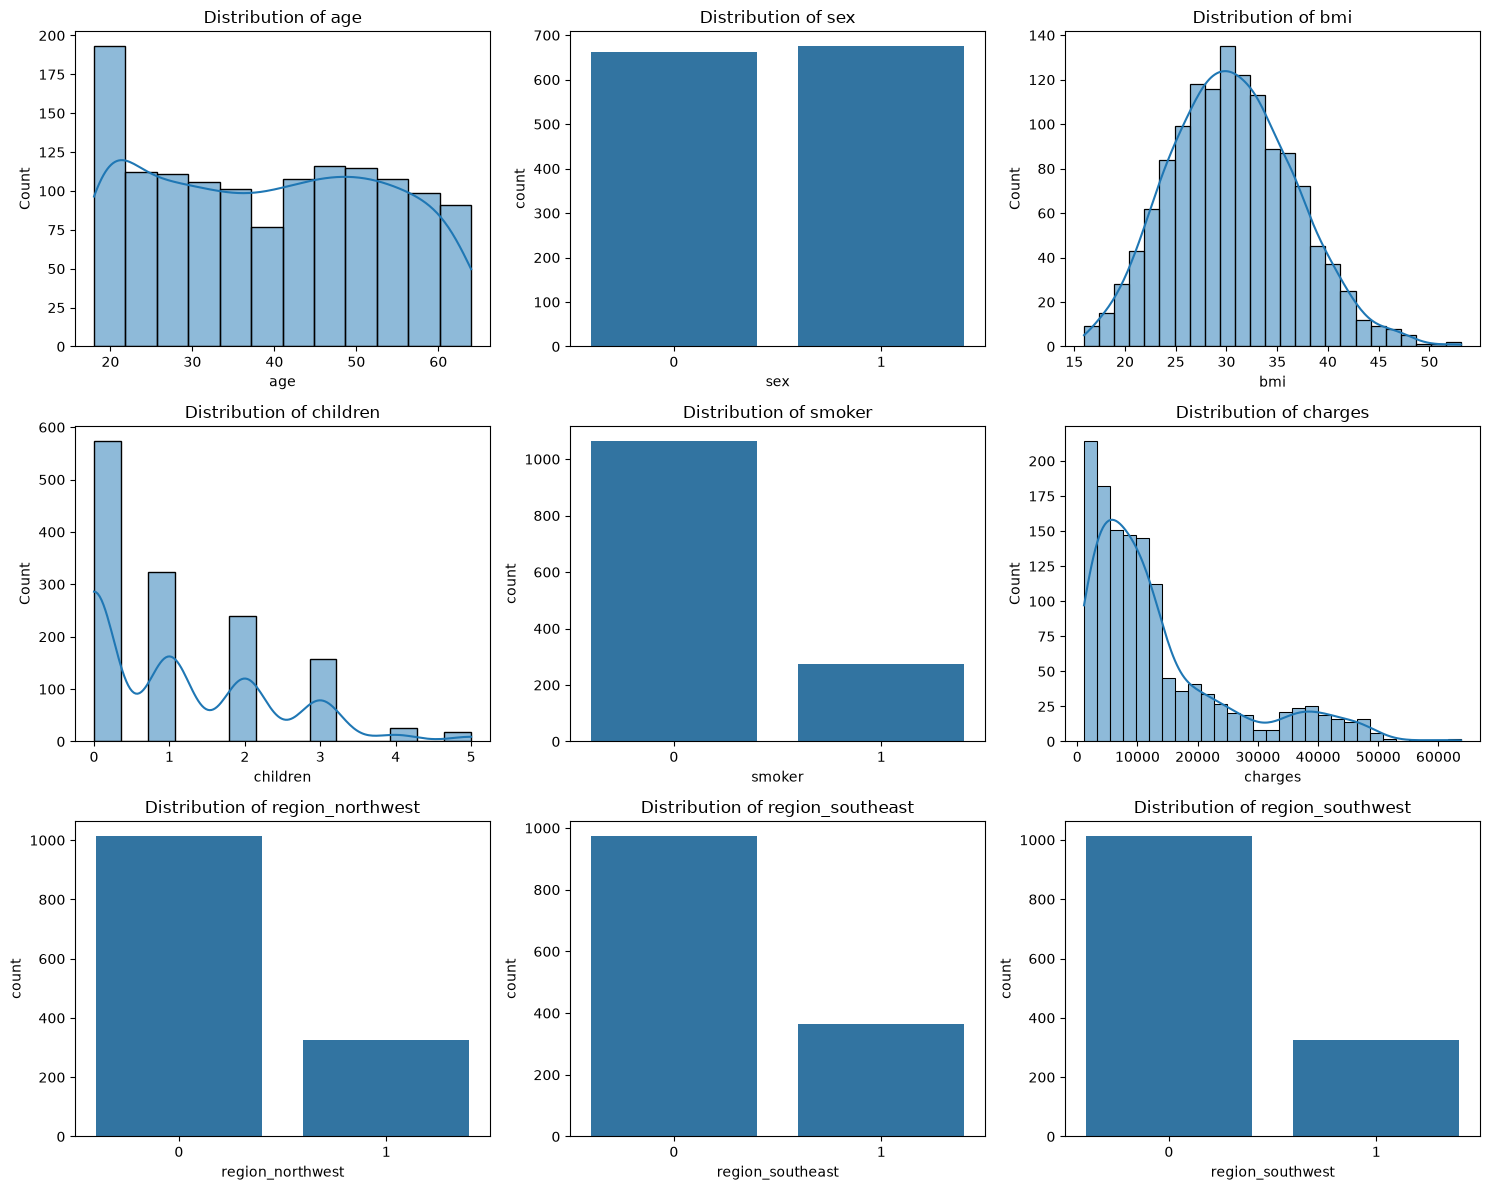

Correlation with charges:


charges             1.000000
smoker              0.787234
age                 0.298308
bmi                 0.198401
region_southeast    0.073578
children            0.067389
sex                 0.058044
region_northwest   -0.038695
region_southwest   -0.043637
Name: charges, dtype: float64

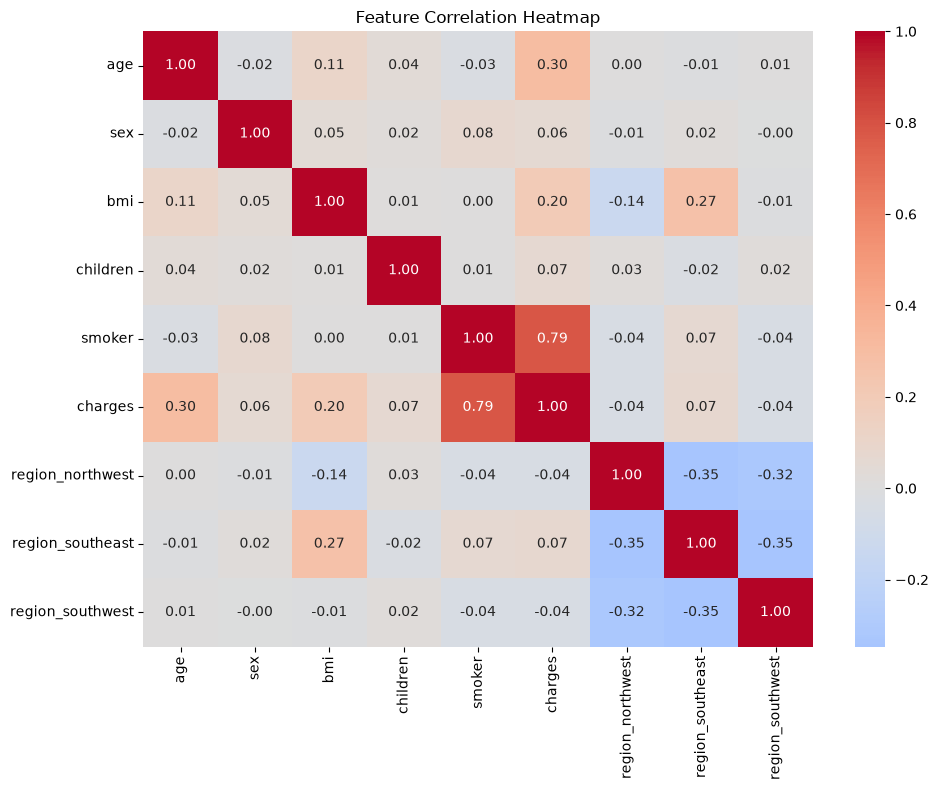

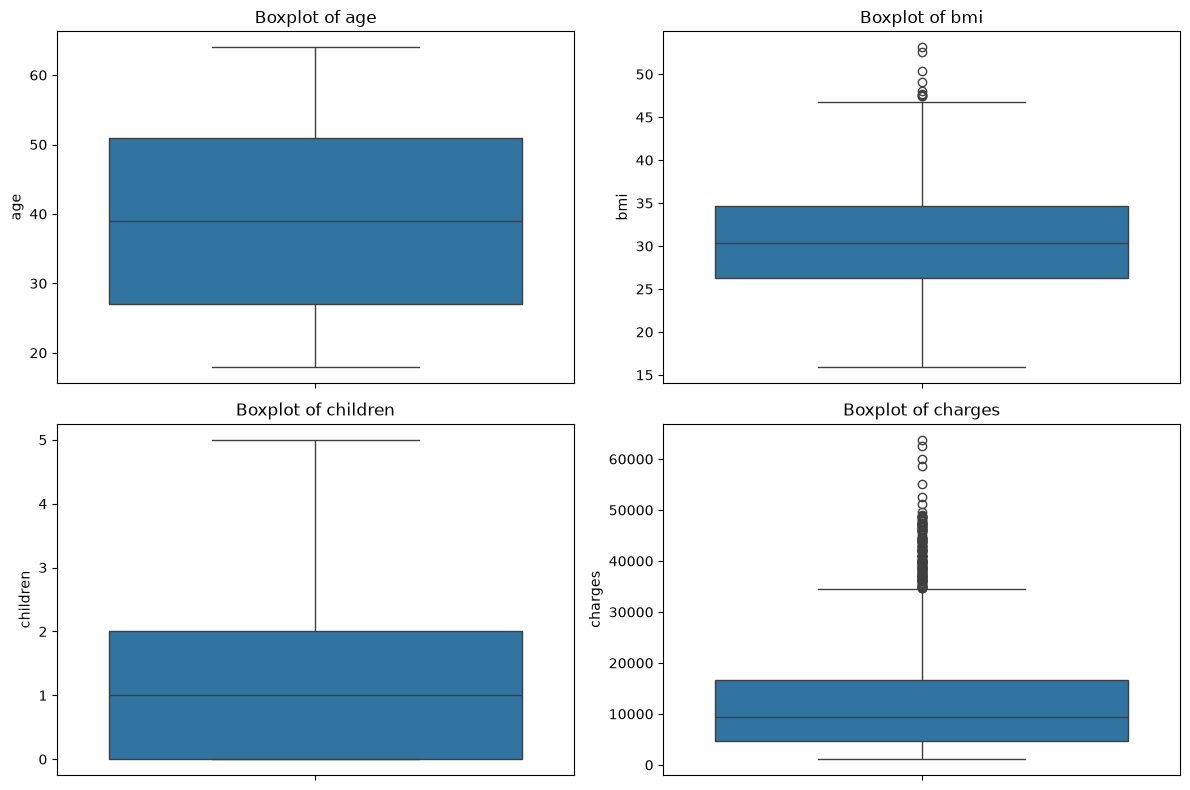

In [11]:
continuous_features = ["age", "bmi", "children", "charges"]
encoded_features = [col for col in medical_encoded_df.columns if col not in continuous_features]

# Distributions of all features
distribution_fig, distribution_axes = plt.subplots(3, 3, figsize=(15, 12))
distribution_axes = distribution_axes.flatten()

for plot_ax, feature_name in zip(distribution_axes, medical_encoded_df.columns):
    if feature_name in continuous_features:
        sns.histplot(data=medical_encoded_df, x=feature_name, kde=True, ax=plot_ax)
    else:
        sns.countplot(data=medical_encoded_df, x=feature_name, ax=plot_ax)
    plot_ax.set_title(f"Distribution of {feature_name}")

plt.tight_layout()
plt.show()

# Correlations, with a focus on the target
correlation_matrix = medical_encoded_df.corr(numeric_only=True)
print("Correlation with charges:")
display(correlation_matrix["charges"].sort_values(ascending=False))

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# Boxplots for continuous features
boxplot_fig, boxplot_axes = plt.subplots(2, 2, figsize=(12, 8))
for plot_ax, feature_name in zip(boxplot_axes.flatten(), continuous_features):
    sns.boxplot(data=medical_encoded_df, y=feature_name, ax=plot_ax)
    plot_ax.set_title(f"Boxplot of {feature_name}")

plt.tight_layout()
plt.show()

In [12]:
# Summarize the main EDA findings
charge_correlations = correlation_matrix["charges"].drop("charges").sort_values(ascending=False)
smoker_mean_charges = medical_df.groupby("smoker")["charges"].mean()
top_smoker_group = smoker_mean_charges.idxmax()
top_smoker_mean = smoker_mean_charges.max()
other_smoker_mean = smoker_mean_charges.min()

print("EDA Summary")
print(f"• The strongest feature correlation with charges is {charge_correlations.index[0]} "
    f"({charge_correlations.iloc[0]:.2f}); age and BMI have weaker positive correlations.")
print(f"• Smoking status shows a large difference in average charges: "
    f"${top_smoker_mean:,.0f} for smokers versus ${other_smoker_mean:,.0f} for non-smokers.")
print("• Charges are right-skewed, with high-cost outliers.")
print("• Sex, children, and region have weak correlations with charges in this dataset.")
print(f"• Missing values: {medical_df.isna().sum().sum()}; duplicate rows remaining: "
    f"{medical_df.duplicated().sum()}.")

EDA Summary
• The strongest feature correlation with charges is smoker (0.79); age and BMI have weaker positive correlations.
• Smoking status shows a large difference in average charges: $32,050 for smokers versus $8,441 for non-smokers.
• Charges are right-skewed, with high-cost outliers.
• Sex, children, and region have weak correlations with charges in this dataset.
• Missing values: 0; duplicate rows remaining: 0.


### 3. Missing Values & Outlier Treatment
##### •	Check for missing values and treat them if any
##### •	Check if there are any outliers.


In [13]:
# Check and treat missing values
missing_before = medical_df.isna().sum()
print("Missing values before treatment:")
display(missing_before[missing_before > 0])

for col in medical_df.columns:
    if medical_df[col].isna().any():
        if pd.api.types.is_numeric_dtype(medical_df[col]):
            medical_df[col] = medical_df[col].fillna(medical_df[col].median())
        else:
            medical_df[col] = medical_df[col].fillna(medical_df[col].mode()[0])

# Detect and cap outliers in numeric predictors (leave target charges unchanged)
predictor_cols = ["age", "bmi", "children"]
outlier_rows = []

for col in predictor_cols:
    q1 = medical_df[col].quantile(0.25)
    q3 = medical_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((medical_df[col] < lower) | (medical_df[col] > upper)).sum()

    outlier_rows.append({
        "feature": col,
        "outlier_count": count,
        "lower_bound": lower,
        "upper_bound": upper
    })
    medical_df[col] = medical_df[col].clip(lower=lower, upper=upper)

outlier_summary = pd.DataFrame(outlier_rows).set_index("feature")
print("Predictor outlier summary (values capped at IQR bounds):")
display(outlier_summary)

print("Missing values remaining:", medical_df.isna().sum().sum())
print("Charges outliers are retained because charges is the prediction target.")

Missing values before treatment:


Series([], dtype: int64)

Predictor outlier summary (values capped at IQR bounds):


,outlier_count,lower_bound,upper_bound
feature,,,
age,0,-9.000,87.000
bmi,9,13.675,47.315
children,0,-3.000,5.000


Missing values remaining: 0
Charges outliers are retained because charges is the prediction target.


### 4. Feature Engineering & Preprocessing
##### •	Encode categorical variables (sex, smoker, region)
##### •	Feature scaling for numerical values (StandardScaler / MinMaxScaler)
##### •	Check for skewness and treat it if required.


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Inspect skewness before deciding whether to transform features
skewness = medical_df[["age", "bmi", "children", "charges"]].skew()
display(skewness.rename("skewness").to_frame())

# Define predictors and target
X = medical_df.drop(columns="charges")
y = medical_df["charges"]

numeric_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

# Scale numeric predictors and one-hot encode categorical predictors
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ],
    remainder="drop"
)

print("Preprocessor configured; fit it on the training data during model building.")
print("No predictor skew transformation is applied: children is a discrete count, "
      "and charges is retained in dollars for model evaluation.")

,skewness
age,0.054781
bmi,0.232892
children,0.937421
charges,1.515391


Preprocessor configured; fit it on the training data during model building.
No predictor skew transformation is applied: children is a discrete count, and charges is retained in dollars for model evaluation.


### 5. Model Building: Try Multiple Regressors
#### Use all the regression-based models to train and test the data:
##### •	Linear Regression
##### •	Decision Tree Regressor
##### •	Random Forest Regressor
##### •	SVR
##### •	KNN
##### •	Ensemble Learning methods


In [15]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor,
    ExtraTreesRegressor,
)

# Split once so every model is evaluated on the same rows
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

regressors = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "SVR": SVR(),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}

model_pipelines = {
    name: Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("regressor", regressor),
    ])
    for name, regressor in regressors.items()
}

# Fit each model on the training data
for name, pipeline in model_pipelines.items():
    pipeline.fit(X_train, y_train)
    print(f"{name} trained.")

Linear Regression trained.
Decision Tree trained.
Random Forest trained.
SVR trained.
KNN trained.
Gradient Boosting trained.
AdaBoost trained.
Extra Trees trained.


### 6. Model Evaluation & Overfitting Check
#### •	Use metrics:
##### o	Mean Absolute Error (MAE)
##### o	Mean Squared Error (MSE)
##### o	Root Mean Squared Error (RMSE)
##### o	R² Score
##### o	Adjusted R² Score
#### •	Compare performance on both datasets (Training and testing) to detect overfitting


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_metrics(y_true, y_pred, n_features):
    n = len(y_true)
    r2 = r2_score(y_true, y_pred)
    adjusted_r2 = (
        1 - (1 - r2) * (n - 1) / (n - n_features - 1)
        if n > n_features + 1 else np.nan
    )

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2,
        "Adjusted R²": adjusted_r2,
    }

evaluation_rows = []

for model_name, fitted_pipeline in model_pipelines.items():
    # Count the encoded features used by the fitted preprocessor.
    n_features = len(
        fitted_pipeline.named_steps["preprocessor"].get_feature_names_out()
    )

    train_metrics = regression_metrics(
        y_train, fitted_pipeline.predict(X_train), n_features
    )
    test_metrics = regression_metrics(
        y_test, fitted_pipeline.predict(X_test), n_features
    )

    evaluation_rows.append({
        "Model": model_name,
        **{f"Train {key}": value for key, value in train_metrics.items()},
        **{f"Test {key}": value for key, value in test_metrics.items()},
        "Train-Test R² Gap": train_metrics["R²"] - test_metrics["R²"],
    })

evaluation_df = pd.DataFrame(evaluation_rows).set_index("Model")
evaluation_df["Overfitting (Y/N)"] = np.where(
    evaluation_df["Train-Test R² Gap"] > 0.10, "Y", "N"
)

display(evaluation_df.round(3).sort_values("Test RMSE"))
print("Overfitting is flagged when the train–test R² gap exceeds 0.10.")

,Train MAE,Train MSE,Train RMSE,Train R²,Train Adjusted R²,Test MAE,Test MSE,Test RMSE,Test R²,Test Adjusted R²,Train-Test R² Gap,Overfitting (Y/N)
Model,,,,,,,,,,,,
Gradient Boosting,2091.809,1.461306e+07,3822.703,0.893,0.892,2493.319,1.765877e+07,4202.234,0.904,0.900,-0.011,N
Random Forest,1013.243,3.294156e+06,1814.981,0.976,0.976,2537.205,2.122710e+07,4607.287,0.884,0.880,0.091,N
AdaBoost,3788.740,2.339780e+07,4837.127,0.829,0.827,3902.995,2.365024e+07,4863.151,0.871,0.866,-0.042,N
Extra Trees,0.000,0.000000e+00,0.000,1.000,1.000,2703.780,2.749850e+07,5243.901,0.850,0.844,0.150,Y
Linear Regression,4186.072,3.696781e+07,6080.116,0.730,0.727,4181.898,3.545290e+07,5954.234,0.807,0.799,-0.077,N
Decision Tree,0.000,0.000000e+00,0.000,1.000,1.000,2708.301,3.652874e+07,6043.901,0.801,0.793,0.199,Y
KNN,2906.891,2.321226e+07,4817.910,0.830,0.829,3836.000,4.066522e+07,6376.929,0.779,0.769,0.052,N
SVR,8082.664,1.505035e+08,12267.986,-0.099,-0.111,9260.363,2.080907e+08,14425.350,-0.132,-0.181,0.033,N


Overfitting is flagged when the train–test R² gap exceeds 0.10.


### 7. Hyperparameter Tuning
##### •	Use GridSearchCV or RandomizedSearchCV to optimize the best-performing models
##### •	Document best parameters and improvement in performance


In [17]:
from sklearn.model_selection import GridSearchCV

tuning_configs = {
    "Gradient Boosting": {
        "estimator": GradientBoostingRegressor(random_state=42),
        "param_grid": {
            "regressor__n_estimators": [100, 200],
            "regressor__learning_rate": [0.03, 0.05, 0.1],
            "regressor__max_depth": [2, 3],
            "regressor__min_samples_leaf": [2, 5],
        },
    },
    "Random Forest": {
        "estimator": RandomForestRegressor(random_state=42, n_jobs=1),
        "param_grid": {
            "regressor__n_estimators": [100, 200],
            "regressor__max_depth": [None, 10],
            "regressor__min_samples_leaf": [1, 2],
        },
    },
}

tuned_searches = {}
tuning_rows = []

for model_name, config in tuning_configs.items():
    tuning_pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("regressor", config["estimator"]),
    ])

    search = GridSearchCV(
        estimator=tuning_pipeline,
        param_grid=config["param_grid"],
        scoring="neg_root_mean_squared_error",
        cv=5,
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_train, y_train)
    tuned_searches[model_name] = search

    tuned_test_rmse = np.sqrt(
        mean_squared_error(y_test, search.best_estimator_.predict(X_test))
    )
    baseline_test_rmse = evaluation_df.loc[model_name, "Test RMSE"]

    tuning_rows.append({
        "Model": model_name,
        "Best CV RMSE": -search.best_score_,
        "Baseline Test RMSE": baseline_test_rmse,
        "Tuned Test RMSE": tuned_test_rmse,
        "Test RMSE Improvement": baseline_test_rmse - tuned_test_rmse,
        "Best Parameters": search.best_params_,
    })

tuning_results = pd.DataFrame(tuning_rows).set_index("Model")
display(tuning_results.round(3))

# Select the tuned model with the lowest cross-validation RMSE.
best_tuned_name = min(
    tuned_searches,
    key=lambda model: -tuned_searches[model].best_score_
)
best_tuned_model = tuned_searches[best_tuned_name].best_estimator_

print(f"Best tuned model by CV: {best_tuned_name}")
print(f"Best parameters: {tuned_searches[best_tuned_name].best_params_}")

,Best CV RMSE,Baseline Test RMSE,Tuned Test RMSE,Test RMSE Improvement,Best Parameters
Model,,,,,
Gradient Boosting,4600.926,4202.234,4237.879,-35.645,"{'regressor__learning_rate': 0.05, 'regressor_..."
Random Forest,4806.163,4607.287,4442.320,164.967,"{'regressor__max_depth': 10, 'regressor__min_s..."


Best tuned model by CV: Gradient Boosting
Best parameters: {'regressor__learning_rate': 0.05, 'regressor__max_depth': 3, 'regressor__min_samples_leaf': 5, 'regressor__n_estimators': 100}


### 8. Model Comparison Table
#### Create a comparison table like below:

| Model | Train RMSE | Test RMSE | Train R² | Test R² | Overfitting (Y/N) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Linear Regression | | | | | |
| Decision Tree | | | | | |
| Random Forest | | | | | |
| Gradient Boosting | | | | | |
| Best Model (e.g. XGB) | | | | | |

#### •	Create a simple UI where user inputs age, sex, BMI, smoker, etc. and receives a predicted insurance charge

In [19]:
from IPython.display import display

# Model comparison table: four baseline models plus the best tuned model
comparison_models = [
	"Linear Regression",
	"Decision Tree",
	"Random Forest",
	"Gradient Boosting",
]

comparison_rows = []
for model_name in comparison_models:
	row = evaluation_df.loc[model_name]
	comparison_rows.append({
		"Model": model_name,
		"Train RMSE": row["Train RMSE"],
		"Test RMSE": row["Test RMSE"],
		"Train R²": row["Train R²"],
		"Test R²": row["Test R²"],
		"Overfitting (Y/N)": row["Overfitting (Y/N)"],
	})

best_train_metrics = regression_metrics(
	y_train, best_tuned_model.predict(X_train), n_features
)
best_test_metrics = regression_metrics(
	y_test, best_tuned_model.predict(X_test), n_features
)

comparison_rows.append({
	"Model": f"Best Model ({best_tuned_name}, tuned)",
	"Train RMSE": best_train_metrics["RMSE"],
	"Test RMSE": best_test_metrics["RMSE"],
	"Train R²": best_train_metrics["R²"],
	"Test R²": best_test_metrics["R²"],
	"Overfitting (Y/N)": (
		"Y" if best_train_metrics["R²"] - best_test_metrics["R²"] > 0.10 else "N"
	),
})

comparison_df = pd.DataFrame(comparison_rows).set_index("Model")
display(comparison_df.round(3))


,Train RMSE,Test RMSE,Train R²,Test R²,Overfitting (Y/N)
Model,,,,,
Linear Regression,6080.116,5954.234,0.730,0.807,N
Decision Tree,0.000,6043.901,1.000,0.801,Y
Random Forest,1814.981,4607.287,0.976,0.884,N
Gradient Boosting,3822.703,4202.234,0.893,0.904,N
"Best Model (Gradient Boosting, tuned)",4215.097,4237.879,0.870,0.902,N


In [24]:
# Extract the fitted scaler from the tuned model's preprocessing pipeline.
scaler = best_tuned_model.named_steps["preprocessor"].named_transformers_["numeric"]

age = int(input("Age: "))
sex = input("Sex (female/male): ").strip().lower()
bmi = float(input("BMI: "))
children = int(input("Number of children: "))
smoker = input("Smoker (yes/no): ").strip().lower()
region = input("Region (northeast/northwest/southeast/southwest): ").strip().lower()

user_input = pd.DataFrame([{
    "age": age,
    "sex": sex,
    "bmi": bmi,
    "children": children,
    "smoker": smoker,
    "region": region,
}])

# The pipeline applies the extracted scaler and categorical encoder automatically.
predicted_charge = best_tuned_model.predict(user_input)[0]
test_r2 = r2_score(y_test, best_tuned_model.predict(X_test))

print(f"\nPredicted insurance charge: ${predicted_charge:,.2f}")
print(f"Test-set R² performance ratio: {test_r2:.2%}")


Predicted insurance charge: $48,520.13
Test-set R² performance ratio: 90.23%


In [25]:
import joblib

# Save the COMPLETE fitted pipeline (preprocessing + trained regression model).
# In Streamlit, load this file and call pipeline.predict(raw_input_dataframe).
# Do not call scaler.transform() on the raw input: categorical columns must first
# pass through the fitted OneHotEncoder inside the pipeline.
joblib.dump(best_tuned_model, "best_tuned_model.pkl")

print("Saved complete model pipeline to best_tuned_model.pkl")

['scaler.pkl']

## Streamlit deployment: use the saved pipeline

The `best_tuned_model.pkl` file contains both the fitted `ColumnTransformer` and the trained model. Pass the original input columns (`age`, `sex`, `bmi`, `children`, `smoker`, `region`) to `predict()`.

**Do not use** `scaler.transform(input_data)` in `app.py`. The extracted numeric scaler only expects numeric columns, and it does not encode `sex`, `smoker`, or `region`. The complete pipeline handles scaling and one-hot encoding in the correct order.

Example for `app.py`:

```python
import joblib
import pandas as pd
import streamlit as st

model = joblib.load("best_tuned_model.pkl")

st.title("Medical Insurance Cost Prediction")

age = st.number_input("Age", min_value=18, max_value=100, value=30, step=1)
sex = st.selectbox("Sex", ["female", "male"])
bmi = st.number_input("BMI", min_value=10.0, max_value=80.0, value=25.0, step=0.1)
children = st.number_input("Number of children", min_value=0, max_value=10, value=0, step=1)
smoker = st.selectbox("Smoker", ["no", "yes"])
region = st.selectbox(
    "Region",
    ["northeast", "northwest", "southeast", "southwest"]
)

if st.button("Predict insurance charges"):
    input_data = pd.DataFrame([{
        "age": age,
        "sex": sex,
        "bmi": bmi,
        "children": children,
        "smoker": smoker,
        "region": region,
    }])

    prediction = model.predict(input_data)[0]
    st.success(f"Predicted insurance charges: ${prediction:,.2f}")
```

Keep `app.py` and `best_tuned_model.pkl` in the same folder, and run `streamlit run app.py`. If you retrain the notebook model, run the model-saving cell again so the `.pkl` file matches the latest pipeline.
